<center><h1>Case_John_HW4</h1></center>
<br>
<br>

Name: John Case
<br>
Github Username: johncase17
<br>
USC ID: 2249212508

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [166]:
from ensurepip import bootstrap

from sklearn.preprocessing import StandardScaler
%pip install -r ../requirements.txt

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import numpy as np
import warnings
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import math
from pathlib import Path
from scipy.stats import bootstrap
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Get the AReM Data Set

In [187]:
#skip 4 rows to extract columns, 5 for data rows only
def extract_data(filepath):
    return pd.read_csv(filepath, sep=r"[,\s]+", comment='#', engine = "python", header = None)
test = extract_data("../data/AReM/standing/dataset13.csv")

# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
def append_data(filepath, df):
    return pd.concat([df, extract_data(filepath)], ignore_index=True)
print(test.head())

      0     1    2      3     4      5     6
0     0  45.0  0.0  12.50  0.87  14.50  0.50
1   250  45.0  0.0  13.00  0.00  14.00  1.00
2   500  45.0  0.0  12.00  0.00  13.50  0.87
3   750  45.0  0.0  13.33  0.47  12.50  0.50
4  1000  45.0  0.0  12.25  0.43  12.75  0.83


### (b) Splitting Data

In [189]:
path1 = "../data/AReM/bending1"
path2 = "../data/AReM/bending2"
path3 = "../data/AReM/cycling"
path4 = "../data/AReM/lying"
path5 = "../data/AReM/sitting"
path6 = "../data/AReM/standing"
path7 = "../data/AReM/walking"
bend_paths = [path1, path2]
other_paths = [path3, path4, path5, path6, path7]
testing_data = [[pd.DataFrame()] * 2, [pd.DataFrame()] * 2, [pd.DataFrame()] * 3, [pd.DataFrame()] * 3, [pd.DataFrame()] * 3, [pd.DataFrame()] * 3, [pd.DataFrame()] * 3]
training_data = [[pd.DataFrame()] * 5, [pd.DataFrame()] * 4, [pd.DataFrame()] * 12, [pd.DataFrame()] * 12, [pd.DataFrame()] * 12, [pd.DataFrame()] * 12, [pd.DataFrame()] * 12]
data_index = 0
#bending loop: train on datasets 1 and 2, test on others
#assumes folders are properly labeled
for folder in bend_paths:
    loc = Path(folder)
    for file in loc.glob("*.csv"):
        i = int(file.stem.removeprefix("dataset")) - 1
        if i < 2:
            testing_data[data_index][i] = extract_data(file)
        else:
            training_data[data_index][i - 2] = extract_data(file)
    data_index = data_index + 1


#other datasets: train on datasets 1, 2, 3, test on others
#assumes folders are properly labeled
for folder in other_paths:
    loc = Path(folder)
    for file in loc.glob("*.csv"):
        i = int(file.stem.removeprefix("dataset")) - 1
        if i < 3:
            testing_data[data_index][i] = extract_data(file)
        else:
            training_data[data_index][i - 3] =extract_data(file)
    data_index = data_index + 1

### (c) Feature Extraction

In [4]:
#flatten + test
flatened_data = [dframe for list in (testing_data + training_data) for dframe in list]
print(len(flatened_data))
print(flatened_data[0].head())

#flatten + test
flatened_data = [dframe for list in (testing_data + training_data) for dframe in list]
print(len(flatened_data))
print(flatened_data[0].head())

feature_names = ['avg_rss12','var_rss12','avg_rss13','var_rss13','avg_rss23','var_rss23']
output_columns = ['Instance', 'min1', 'max1', 'mean1', 'median1', 'SD1', '1st_quart1', '3rd_quart1', 'min2', 'max2', 'mean2', 'median2', 'SD2', '1st_quart2', '3rd_quart2', 'min3', 'max3', 'mean3', 'median3', 'SD3', '1st_quart3', '3rd_quart3', 'min4', 'max4', 'mean4', 'median4', 'SD4', '1st_quart4', '3rd_quart4', 'min5', 'max5', 'mean5', 'median5', 'SD5', '1st_quart5', '3rd_quart5', 'min6', 'max6', 'mean6', 'median6', 'SD6', '1st_quart6', '3rd_quart6']
output_dataset = pd.DataFrame(np.nan, index=range(len(flatened_data)), columns=output_columns)

#index is the dataframe corresponding to a single dataset
#i tracks which input feature is being processed
#j tracks which time series feature is being used
# 0=min, 1=max, 2=mean, 3= median, 4=SD, 5=1st_quart, 6=3rd_quart
index = 0
while index < 88:
    output_dataset.iloc[index, 0] = index + 1
    for i in range (1,7):
        for j in range (0,7):
            col_num = 1+(i-1)*7+j
            if j == 0:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].min()
            if j == 1:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].max()
            if j == 2:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].mean()
            if j == 3:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].median()
            if j == 4:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].std()
            if j == 5:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].quantile(0.25)
            if j == 6:
                output_dataset.iloc[index, col_num] = flatened_data[index][i].quantile(0.75)
        col_num = col_num + 1
    # feature = feature + 1
    index = index + 1
print(output_dataset)

88
      0      1     2      3     4      5    6
0     0  39.25  0.43  22.75  0.43  33.75  1.3
1   250  39.25  0.43  23.00  0.00  33.00  0.0
2   500  39.25  0.43  23.25  0.43  33.00  0.0
3   750  39.50  0.50  23.00  0.71  33.00  0.0
4  1000  39.50  0.50  24.00  0.00  33.00  0.0
88
      0      1     2      3     4      5    6
0     0  39.25  0.43  22.75  0.43  33.75  1.3
1   250  39.25  0.43  23.00  0.00  33.00  0.0
2   500  39.25  0.43  23.25  0.43  33.00  0.0
3   750  39.50  0.50  23.00  0.71  33.00  0.0
4  1000  39.50  0.50  24.00  0.00  33.00  0.0
    Instance   min1   max1      mean1  median1       SD1  1st_quart1  \
0        1.0  37.25  45.00  40.624792   40.500  1.476967     39.2500   
1        2.0  38.00  45.67  42.812812   42.500  1.435550     42.0000   
2        3.0  12.75  51.00  24.562958   24.250  3.737514     23.1875   
3        4.0   0.00  42.75  27.464604   28.000  3.583582     25.5000   
4        5.0  24.25  45.00  37.177042   36.250  3.581301     34.5000   
5        6

In [6]:
#std for each feature
features = output_dataset.columns.drop('Instance')
std_interval = pd.DataFrame(dtype=object, index=range(len(features)), columns=['feature', 'std', 'lower', 'upper'])
index = 0
for feature in features:
    data = output_dataset[feature].to_numpy()
    std = bootstrap(data=(data,), confidence_level=0.9, statistic=np.std, random_state=42, method='percentile')
    std_interval.loc[index, 'lower'] = std.confidence_interval.low
    std_interval.loc[index, 'upper'] = std.confidence_interval.high
    std_interval.loc[index, 'feature'] = feature
    std_interval.loc[index, 'std'] = output_dataset[feature].std(ddof=0)
    index = index + 1

print(std_interval)

       feature       std     lower      upper
0         min1  9.515445  8.200262  10.691329
1         max1  4.369322  3.338077   5.236803
2        mean1  5.305314  4.683571   5.855863
3      median1  5.409056  4.764524   5.971714
4          SD1  1.762056   1.56142   1.940672
5   1st_quart1  6.118526  5.542267   6.612373
6   3rd_quart1  5.109643  4.318389   5.811497
7         min2       0.0       0.0        0.0
8         max2  5.033882  4.597552    5.37516
9        mean2  1.565194  1.387118    1.69692
10     median2  1.404197  1.230651     1.5343
11         SD2  0.879068  0.798673   0.937313
12  1st_quart2  0.940994   0.82605   1.028968
13  3rd_quart2  2.113157  1.880897    2.28237
14        min3  2.939616  2.740544   3.090272
15        max3  4.847358  4.156121    5.43123
16       mean3   3.98554  3.390391   4.462973
17     median3  4.013397  3.406623   4.508701
18         SD3  0.941316   0.75766   1.119716
19  1st_quart3  4.196608  3.601375    4.66712
20  3rd_quart3  4.147858  3.523439

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

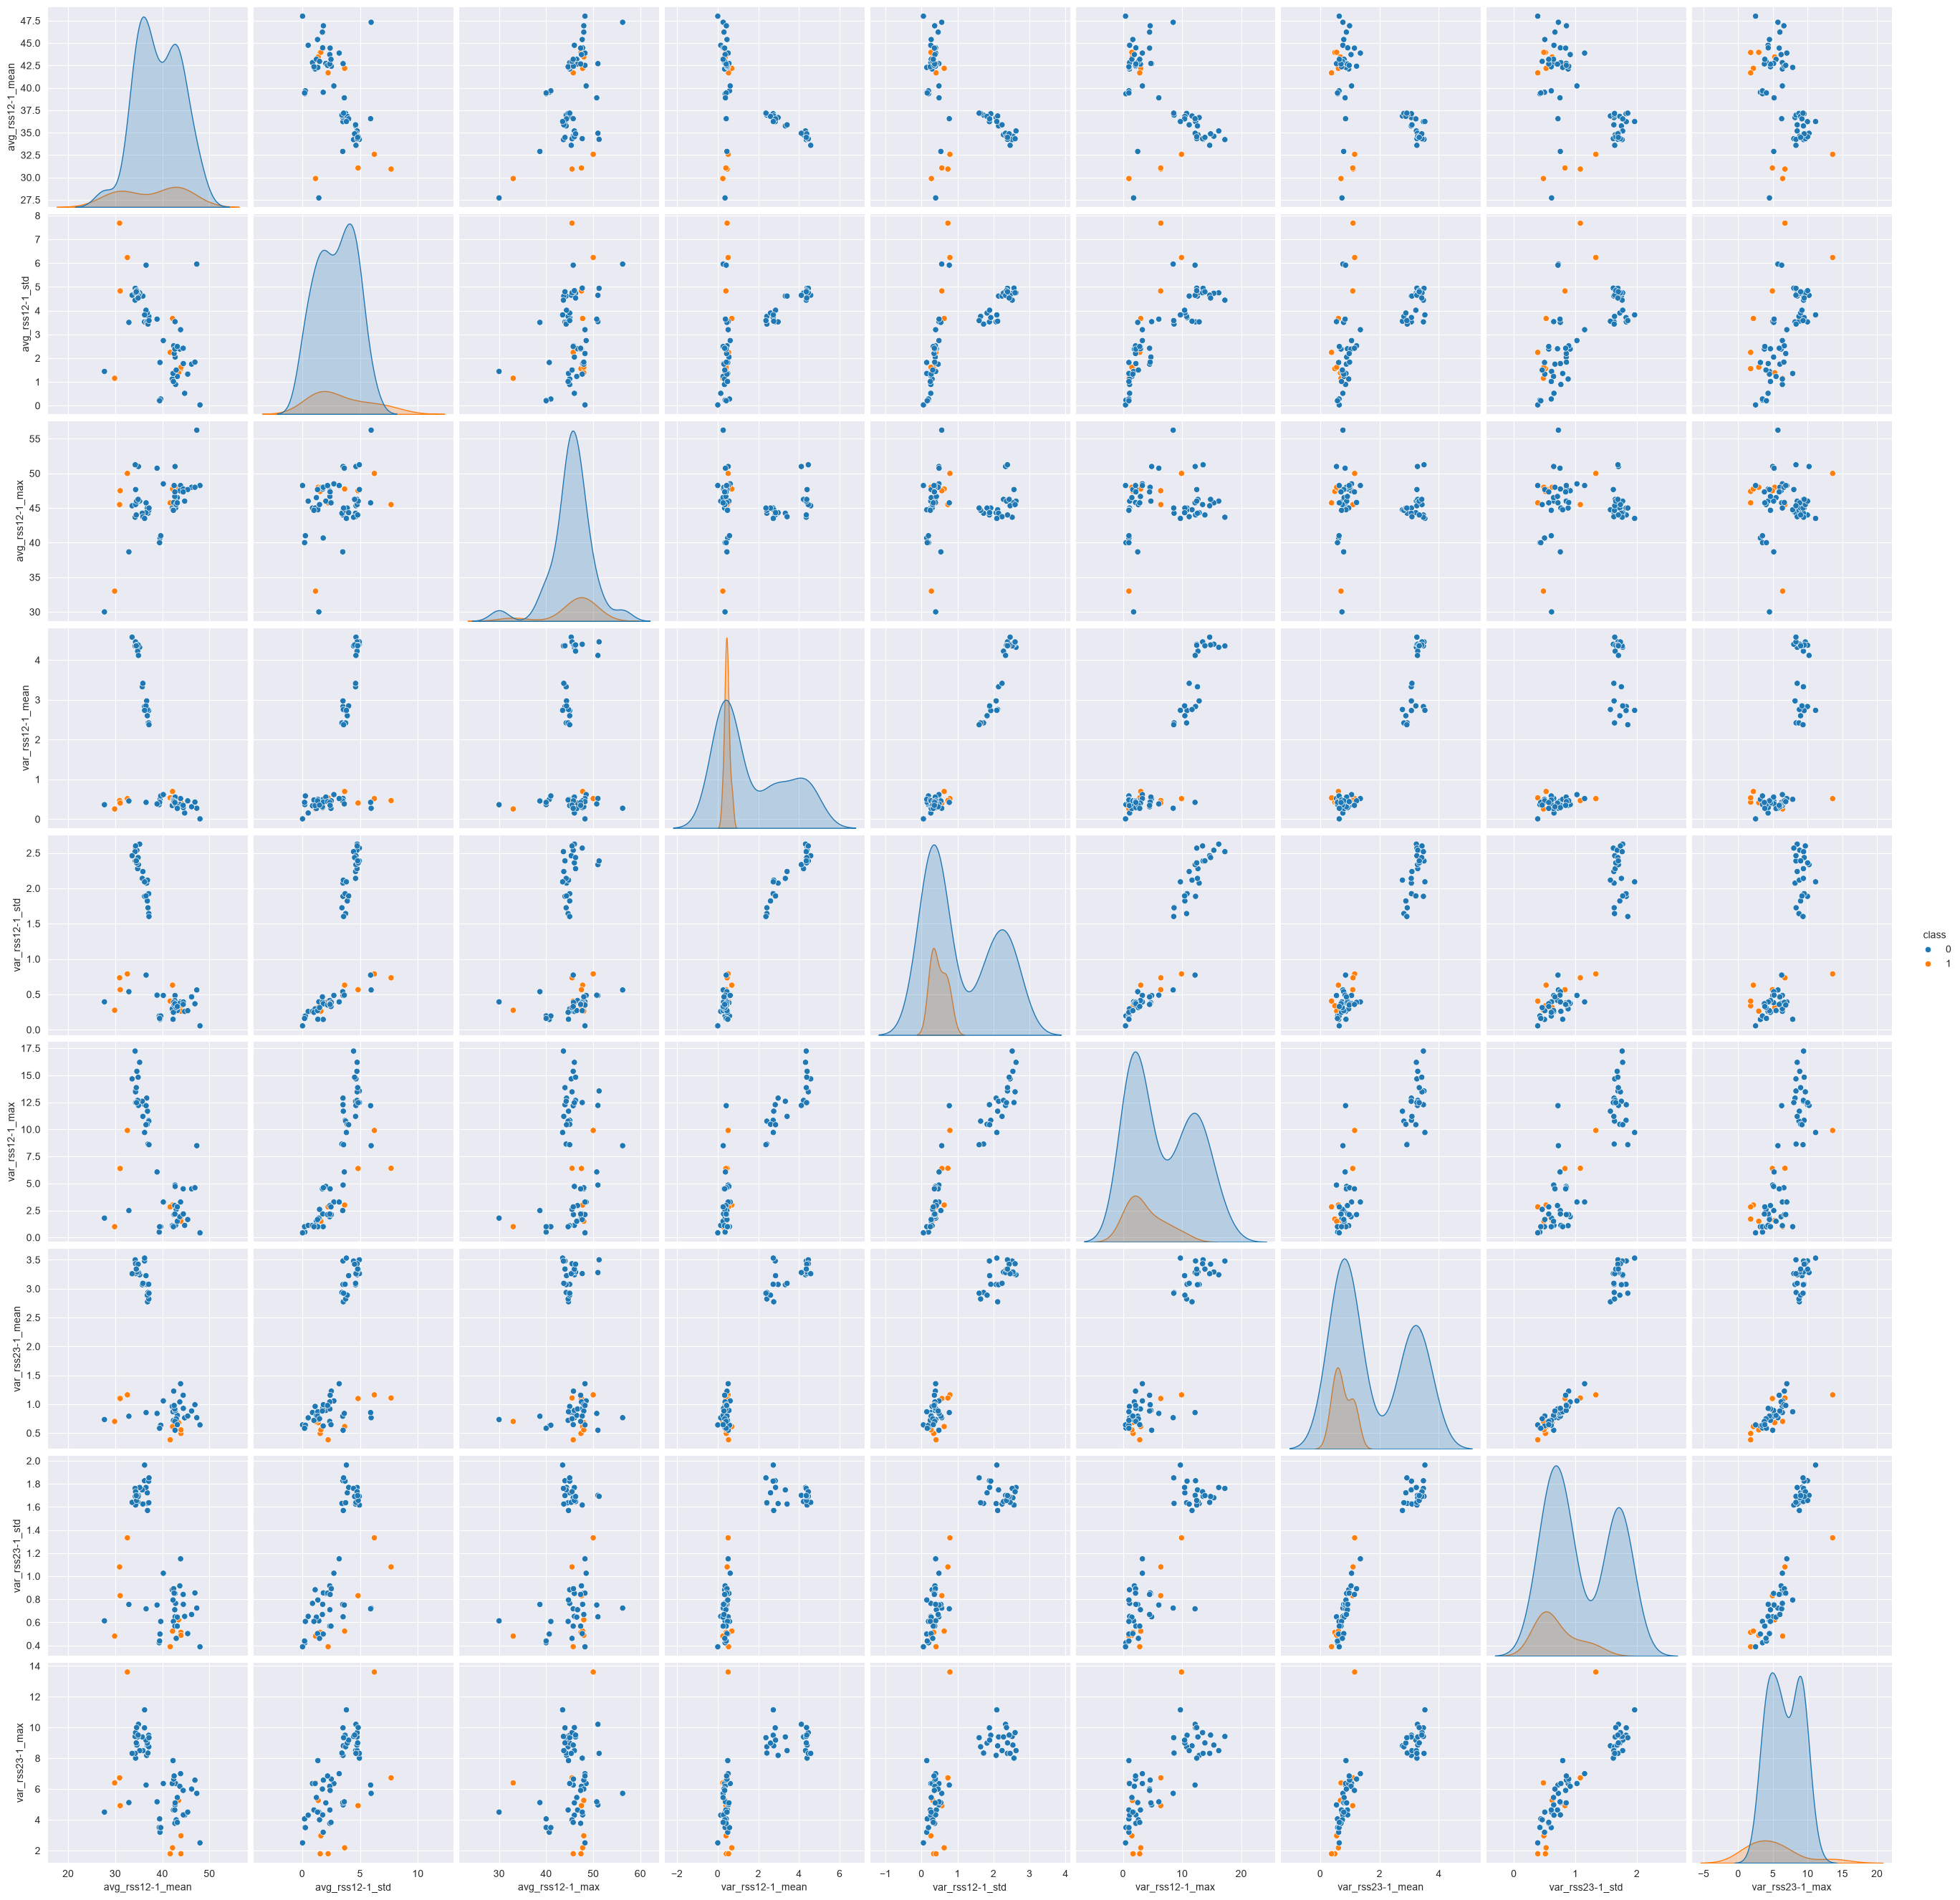

In [148]:
#main features: mean, std, max

#extracts the time series features (index 1, 2, 6) and break into k series
#returns dataframe
def extract_features(dframe, k):
    temp = pd.DataFrame({'avg_rss12': dframe[1], 'var_rss12': dframe[2], 'var_rss23': dframe[6]})
    stride = len(temp) / k
    chunks = []
    for i in range(k):
        start_row = int(i * stride)
        end_row = int((i + 1) * stride)
        chunk = temp.iloc[start_row:end_row].reset_index(drop=True)
        chunk.columns = [f"{col}-{i+1}" for col in chunk.columns]
        chunks.append(chunk)

    return pd.concat(chunks, axis=1)

#applies three selected features mean, std, max to each time series
#returns row with each metric for each col in dframe
def analyze_features(dframe):
    data = {}
    for col in dframe.columns:
        data[col+"_mean"] = dframe[col].mean()
        data[col+"_std"] = dframe[col].std()
        data[col+"_max"] = dframe[col].max()
    return pd.DataFrame([data])
def split_features(train_data, chunks):
    bending_train = pd.DataFrame()
    not_bending_train = pd.DataFrame()
    combined_train = pd.DataFrame
    for i in range(len(train_data)):
        for j in range(len(train_data[i])):
            temp_row = analyze_features(extract_features(train_data[i][j], chunks))
            if i <= 1:
                bending_train = pd.concat([bending_train, temp_row], ignore_index=True)
            else:
                not_bending_train = pd.concat([not_bending_train, temp_row], ignore_index=True)

    #add class column
    bending_train['class'] = 1
    not_bending_train['class'] = 0
    return pd.concat([bending_train, not_bending_train], ignore_index=True)

def split_features_class(train_data, chunks):
    class_train = pd.DataFrame()
    for i in range(len(train_data)):
        for j in range(len(train_data[i])):
            temp_row = analyze_features(extract_features(train_data[i][j], chunks))
            temp_row['class'] = [i]
            class_train = pd.concat([class_train, temp_row], ignore_index=True)
    return class_train
#plot
sns.pairplot(split_features(training_data, 1), hue='class', height=3)

#### ii. Splitted Plots

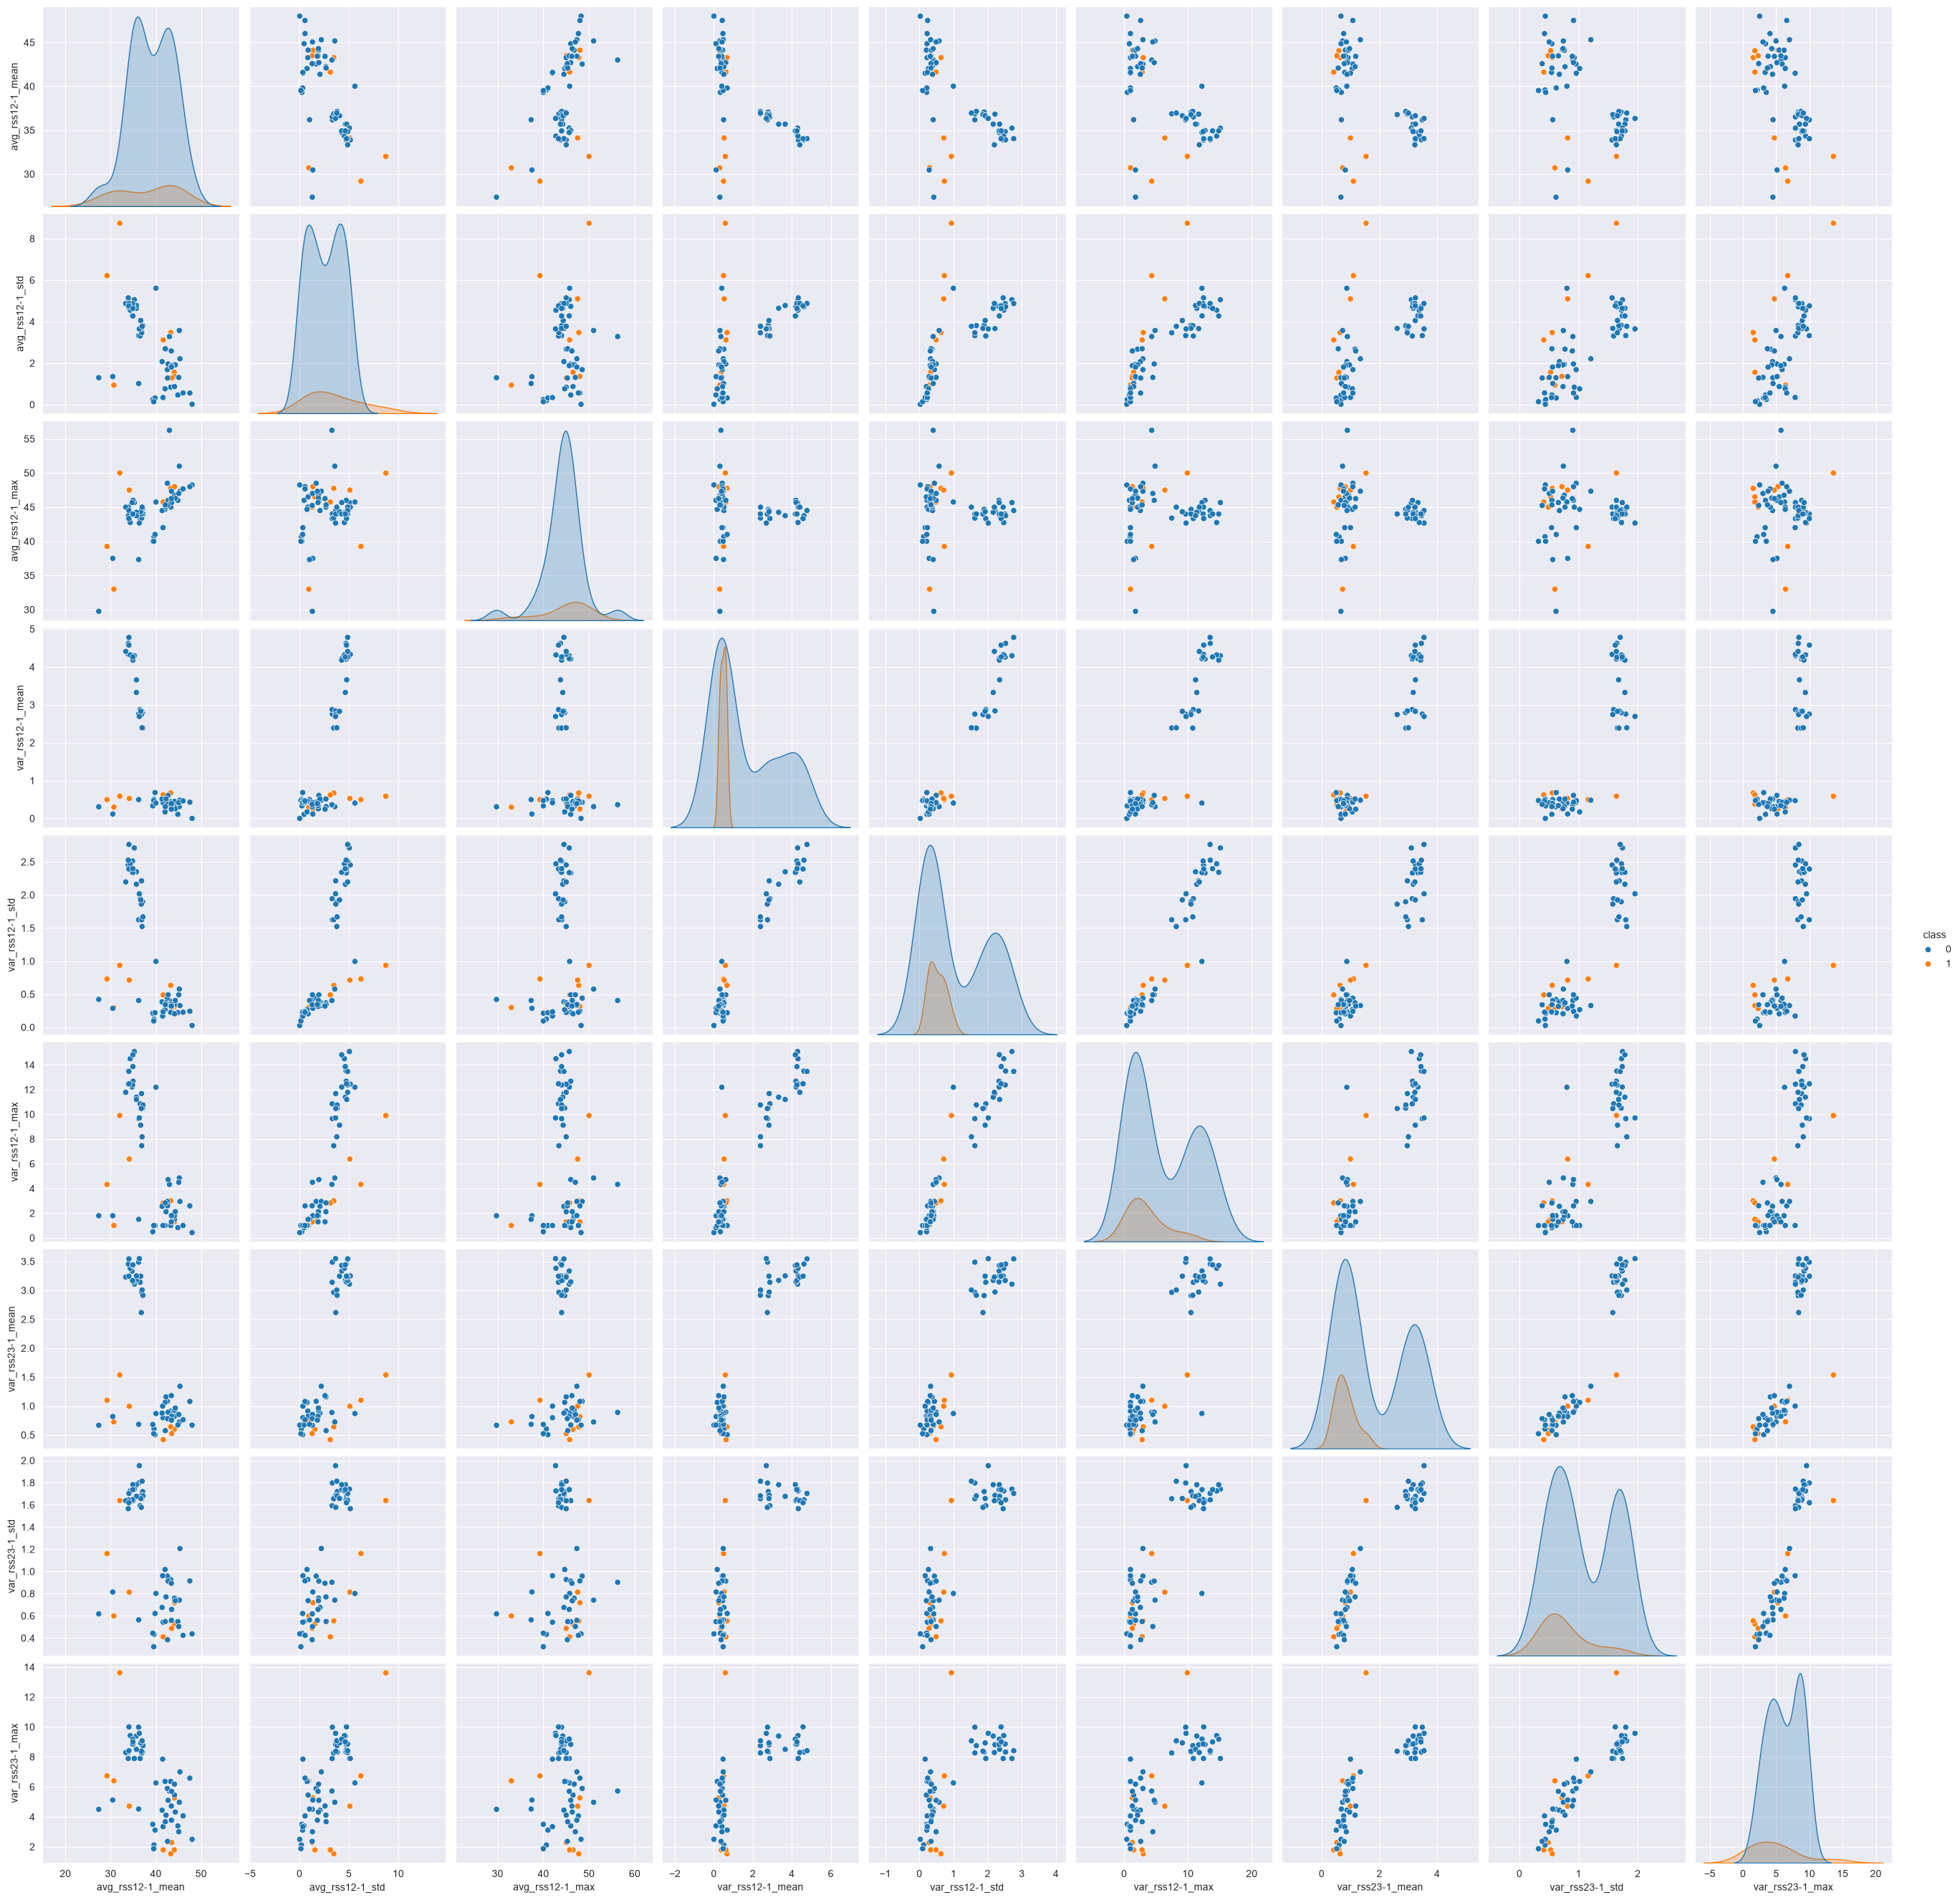

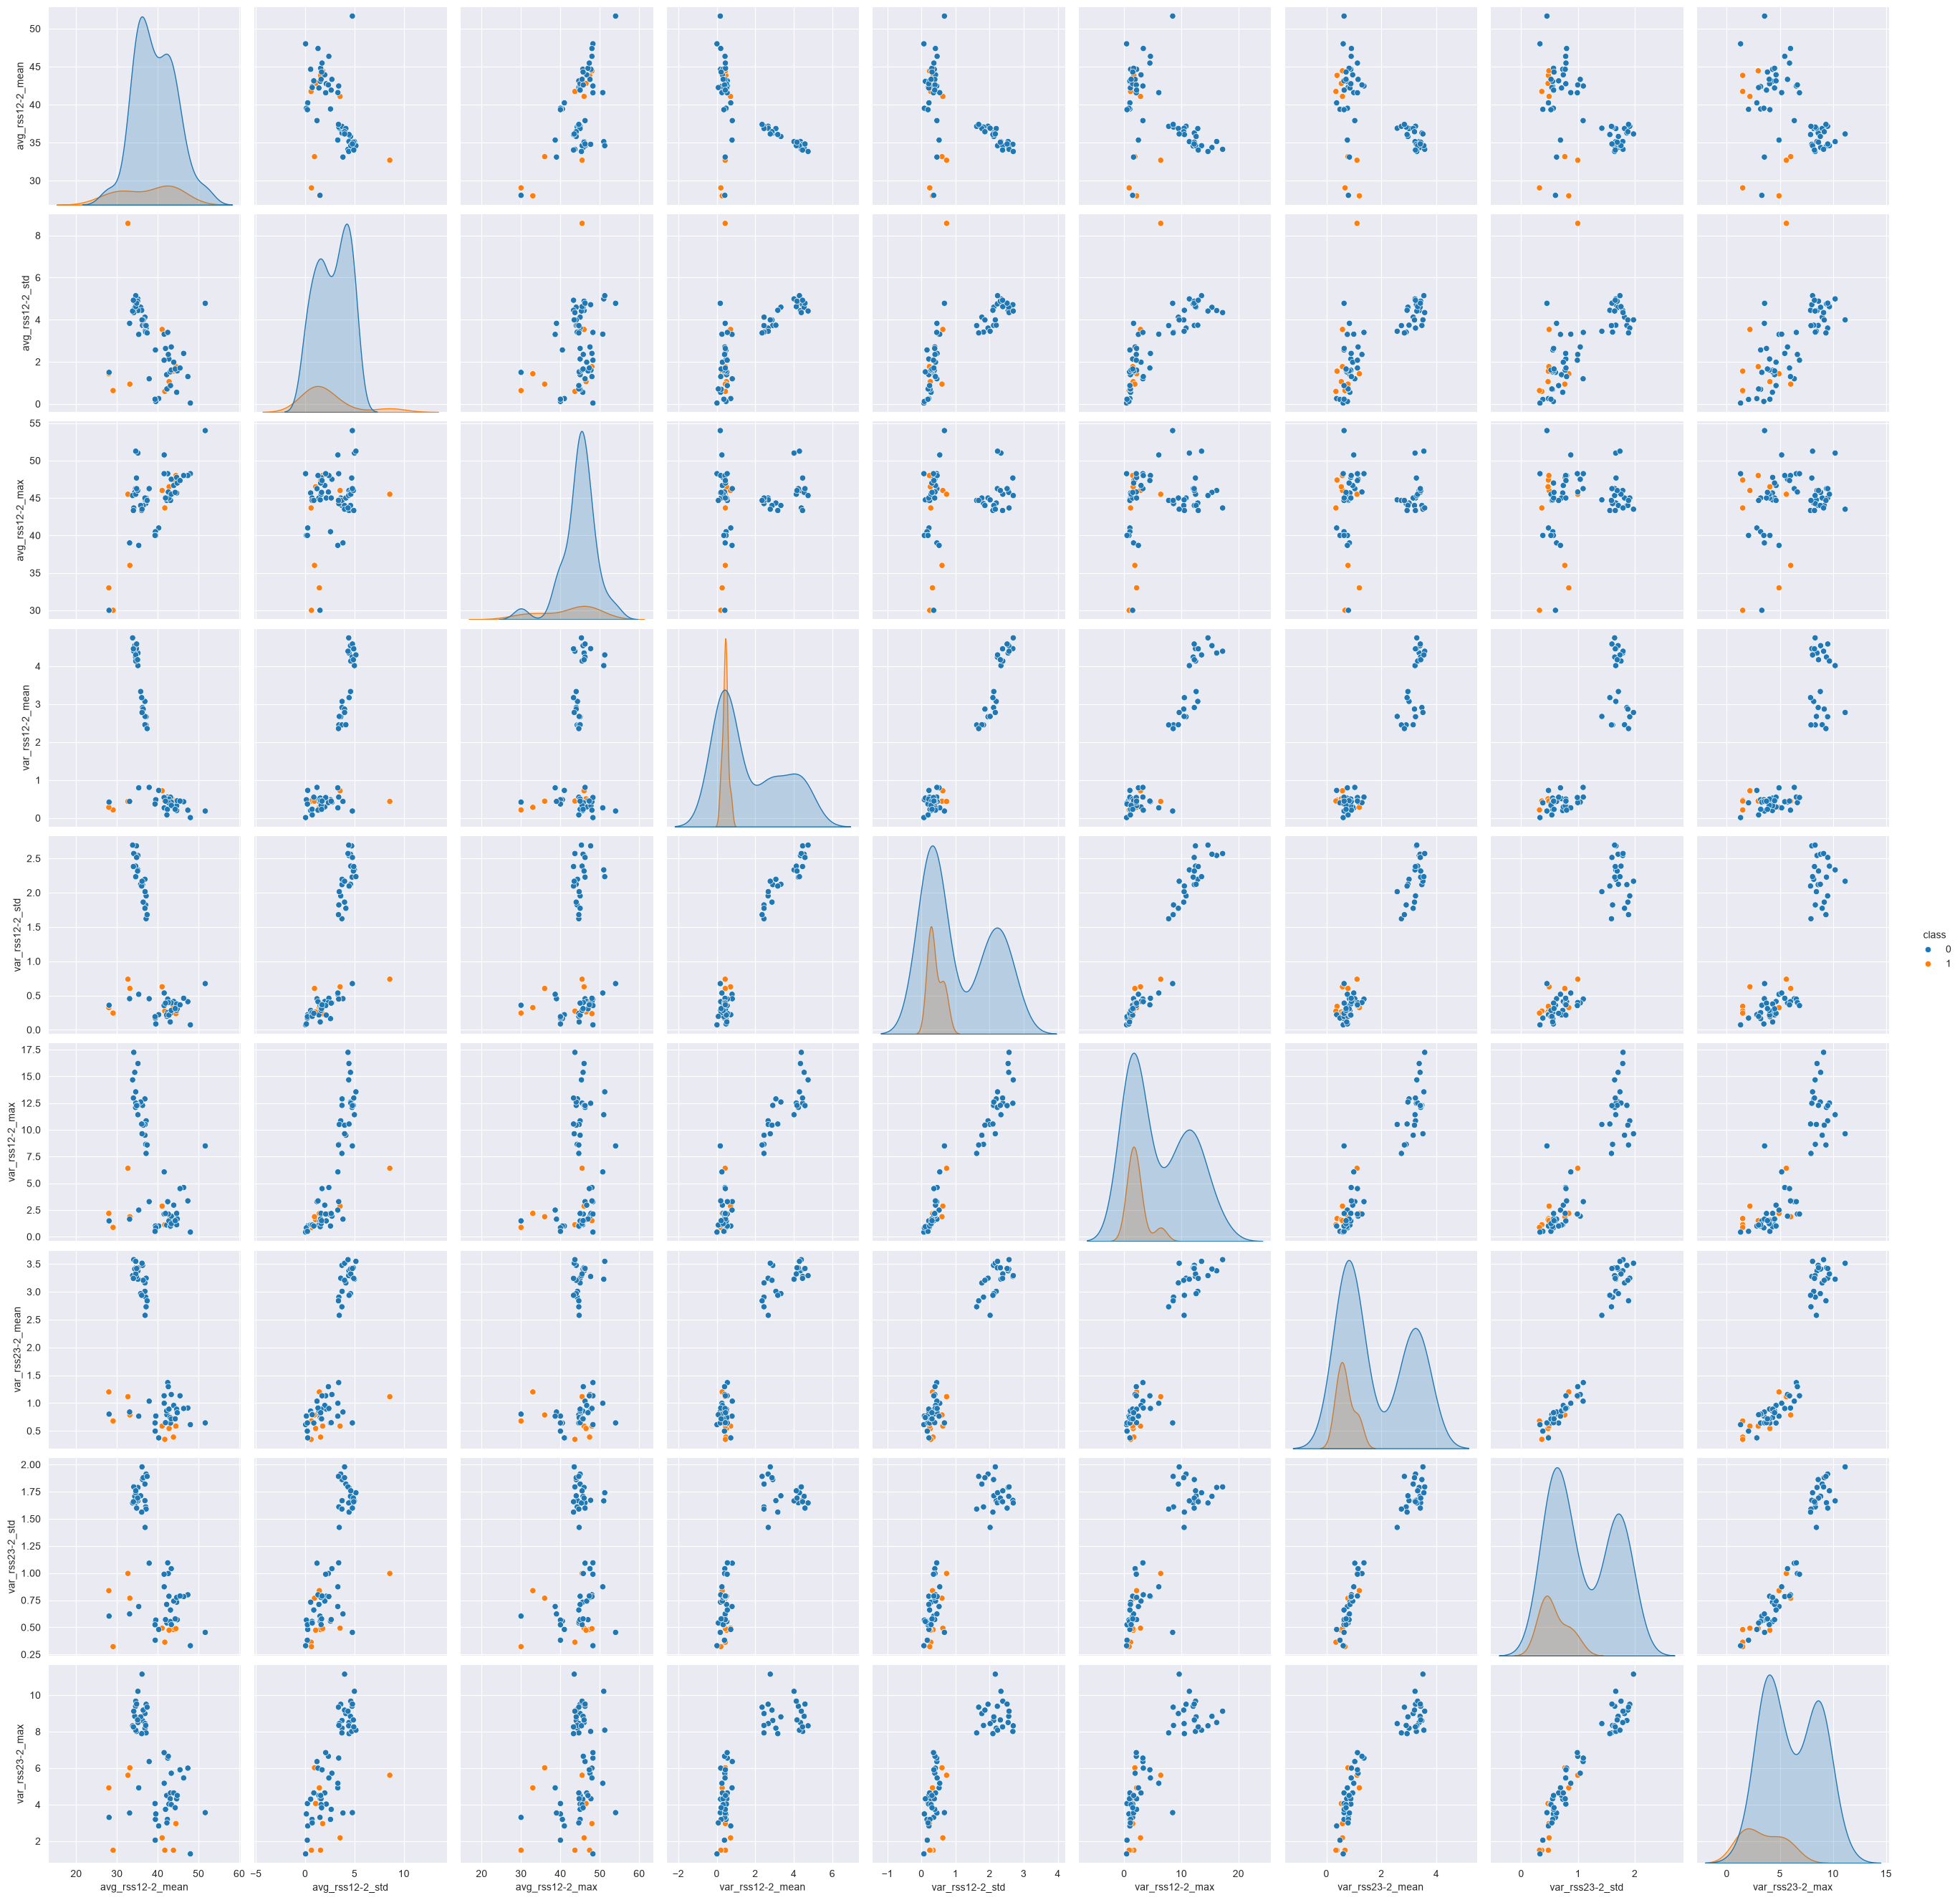

In [58]:
#repeat for 2 chunks
bending_train = pd.DataFrame()
not_bending_train = pd.DataFrame()
combined_train = pd.DataFrame
chunks = 2
for i in range(len(training_data)):
    for j in range(len(training_data[i])):
        temp_row = analyze_features(extract_features(training_data[i][j], chunks))
        if i <= 1:
            bending_train = pd.concat([bending_train, temp_row], ignore_index=True)
        else:
            not_bending_train = pd.concat([not_bending_train, temp_row], ignore_index=True)

#add class column
bend1 = bending_train.iloc[:, :len(bending_train.columns)//2]
bend2 = bending_train.iloc[:, len(bending_train.columns)//2:]
not_bend1 = not_bending_train.iloc[:, :len(not_bending_train.columns)//2]
not_bend2 = not_bending_train.iloc[:, len(not_bending_train.columns)//2:]
bend1['class'] = 1
bend2['class'] = 1
not_bend1['class'] = 0
not_bend2['class'] = 0
combined1 = pd.concat([bend1, not_bend1], ignore_index=True)
combined2 = pd.concat([bend2, not_bend2], ignore_index=True)


#plot
sns.pairplot(combined1, hue='class', height=3)
sns.pairplot(combined2, hue='class', height=3)

There is slightly more overlap for var_rss12, but in general, there is no considerable difference.

In [66]:
reg = LogisticRegression(C=np.inf, max_iter=300)
selector = RFECV(estimator=reg, cv=StratifiedKFold(5), step=0.1, n_jobs=-1, scoring='accuracy')
ts_output = pd.DataFrame({'k': [], 'p': [], 'accuracy': []})
for k in range (1,21):
    data = {}
    sample = split_features(training_data, k)
    selector.fit(sample.drop(columns='class'), sample['class'])
    data['k'] = int(k)
    data['p'] = int(selector.n_features_)
    data['accuracy'] = selector.cv_results_["mean_test_score"].max()
    ts_output = pd.concat([ts_output, pd.DataFrame([data])], ignore_index=True)

#### iii. Time Series Segments

In [75]:
#output cell
print("best combination: \n" + str(ts_output[ts_output['accuracy'] == ts_output['accuracy'].max()]))
print(ts_output)

best combination: 
     k    p  accuracy
0  1.0  7.0  0.942857
       k      p  accuracy
0    1.0    7.0  0.942857
1    2.0    9.0  0.928571
2    3.0   13.0  0.900000
3    4.0   24.0  0.898901
4    5.0   33.0  0.928571
5    6.0   14.0  0.927473
6    7.0   15.0  0.898901
7    8.0   72.0  0.884615
8    9.0   33.0  0.913187
9   10.0   18.0  0.885714
10  11.0   54.0  0.900000
11  12.0   18.0  0.870330
12  13.0    7.0  0.884615
13  14.0  114.0  0.914286
14  15.0   44.0  0.884615
15  16.0    1.0  0.898901
16  17.0   78.0  0.884615
17  18.0   50.0  0.870330
18  19.0  137.0  0.884615
19  20.0  108.0  0.870330


#### iv. Confusion Matrix

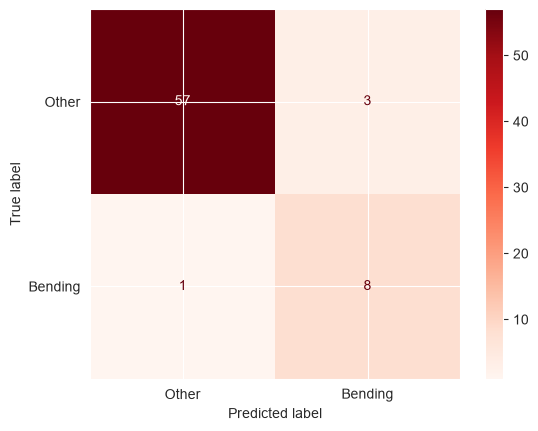

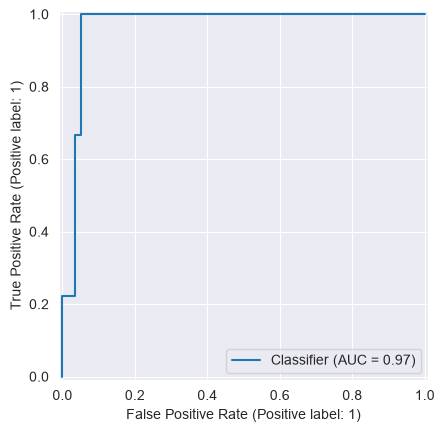

AUC: 0.9685185185185184


In [99]:
#redo best k (1)
sample = split_features(training_data, 1)
sel_x = sample.drop(columns='class')
sel_y = sample['class']
selector.fit(sel_x, sel_y)

#Training Confusion Matrix
c_matrix= confusion_matrix(sel_y, selector.predict(sel_x))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Other', 'Bending'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
scores = selector.predict_proba(sel_x)[:, 1]
auc = roc_auc_score(sel_y, scores)
RocCurveDisplay.from_predictions(sel_y, scores)
plt.show()
print('AUC: ' + str(auc))


In [105]:
#Logistic regression and p-values
filtered_cols = selector.get_feature_names_out()
x_sm = sm.add_constant(sel_x[filtered_cols])
log_reg = sm.Logit(sel_y, x_sm).fit()
yhat = log_reg.predict(x_sm)
prediction = list(map(round, yhat))
b_p_params = pd.DataFrame({'p-values': log_reg.pvalues, 'Bi': log_reg.params})
print('\n' + str(b_p_params))

Optimization terminated successfully.
         Current function value: 0.127217
         Iterations 13

                  p-values         Bi
const             0.250047  10.815957
avg_rss12-1_mean  0.067535  -1.845380
avg_rss12-1_max   0.054026   1.715996
var_rss12-1_mean  0.756094  -3.367490
var_rss12-1_std   0.519588   7.637529
var_rss12-1_max   0.067868  -2.683970
var_rss23-1_mean  0.094298 -19.230119
var_rss23-1_std   0.573505   5.606855


#### v. Test Classifier

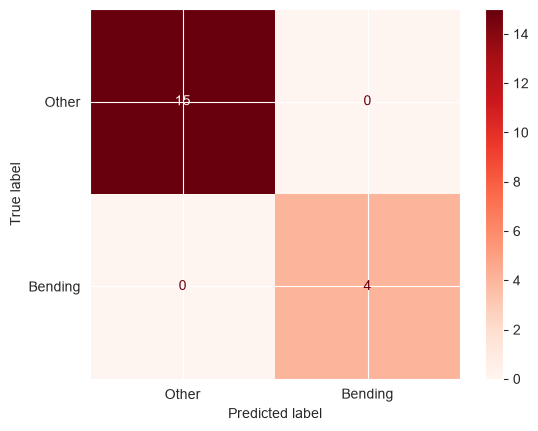

test accuracy: 1.0
test iterations: 19

training accuracy: 0.9420289855072463
training iterations: 69



In [112]:
#testing
test_data = split_features(testing_data, 1)
test_x = test_data.drop(columns='class')
test_y = test_data['class']

c_matrix= confusion_matrix(test_y, selector.predict(test_x))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Other', 'Bending'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

print('test accuracy: '+str(selector.score(test_x, test_y)))
print('test iterations: ' + str(len(test_x)) + '\n')

print('training accuracy: '+str(selector.score(sel_x, sel_y)))
print('training iterations: ' + str(len(sel_x)) + '\n')

#### vi. Separation

The classes are fairly well-separated as training accuracy was high, but there were some errors, so they are not perfectly separable. The Bi values are stable, as they all fit the range of (-20, 11) which is reasonable.

#### vii. Imbalance

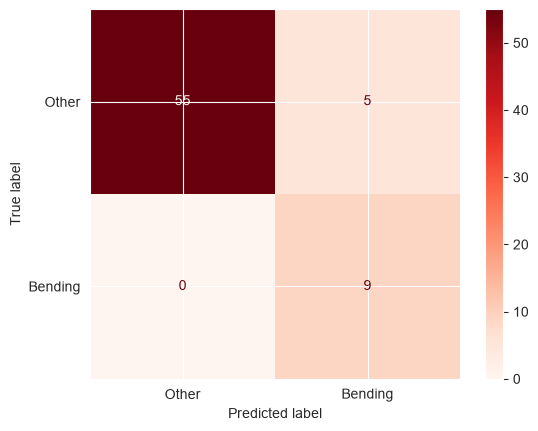

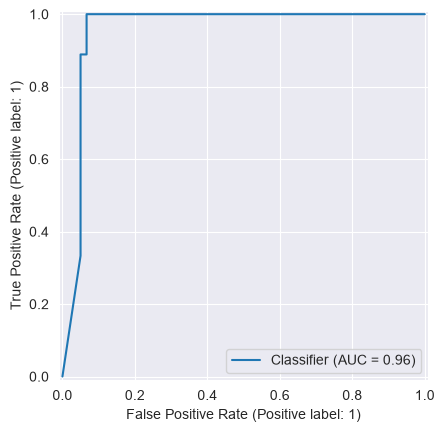

AUC: 0.9564814814814815


In [122]:
#Classes are not balanced: train data ratio is 9:60
min_class = sample['class'].value_counts().min()
balanced_sample = sample.groupby('class').sample(n=min_class, random_state=42).reset_index(drop=True)
bal_x = balanced_sample.drop(columns='class')[filtered_cols]
bal_y = balanced_sample['class']
reg.fit(bal_x, bal_y)
reg.intercept_ = reg.intercept_ + math.log(min_class/60)

#confusion matrix
c_matrix= confusion_matrix(sel_y, reg.predict(sel_x[filtered_cols]))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Other', 'Bending'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
scores = reg.predict_proba(sel_x[filtered_cols])[:, 1]
auc = roc_auc_score(sel_y, scores)
RocCurveDisplay.from_predictions(sel_y, scores)
plt.show()
print('AUC: ' + str(auc))

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [144]:
#find best k
seg = LogisticRegressionCV(use_legacy_attributes=True, solver='liblinear', cv=5, l1_ratios=[1], n_jobs=-1, scoring='accuracy')
ts1_output = pd.DataFrame({'nonzero': [], 'k': [], 'c': [], 'accuracy': []})
for k in range (1,21):
    data = {}
    sample = split_features(training_data, k)
    scaler = StandardScaler()
    x_scaled = scaler.fit_transform(sample.drop(columns='class'))
    seg.fit(x_scaled, sample['class'])
    data['k'] = int(k)
    data['c'] = seg.C_[0]
    data['accuracy'] = seg.scores_[1].mean(axis=0).max()
    data['nonzero'] = ((seg.coef_!=0).sum())
    ts1_output = pd.concat([ts_output, pd.DataFrame([data])], ignore_index=True)



In [154]:
print("best combination: \n" + str(ts1_output[ts1_output['accuracy'] == ts1_output['accuracy'].max()]))
print()
best_k = int(ts1_output.loc[ts1_output['accuracy'].idxmax(), 'k'])
best_c = float(ts1_output.loc[ts1_output['accuracy'].idxmax(), 'c'])
best_l1 = LogisticRegression(C=best_c, solver='liblinear', l1_ratio=1)
sample = split_features(training_data, best_k)
scaler = StandardScaler()
x_scaled = scaler.fit_transform(sample.drop(columns='class'))
best_l1.fit(x_scaled, sample['class'])

#test best_l1
test_sample = split_features(testing_data, best_k)
test_x = scaler.transform(test_sample.drop(columns='class'))
l1_acc = best_l1.score(test_x, test_sample['class'])

print('accuracy: ' + str(l1_acc))

best combination: 
   nonzero    k           c  accuracy
0      8.0  1.0  166.810054       0.9

accuracy: 0.8947368421052632


#### ii. Comparison

The L1-penalized model performs slightly worse at 89.5% test accuracy, compared to the p-values 100% test accuracy. This is minor, as the test sets are smaller than training sets, so higher variance is to be expected. However, the L1 model was easier to implement, as the RFE required an additional loop to select features.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [162]:
# Use split_features_class(data, k) to apply unique classes
#silencing warnings for this loop
with warnings.catch_warnings():
    seg = LogisticRegressionCV(use_legacy_attributes=True, solver='saga', cv=4, l1_ratios=[1], max_iter=2000, scoring='accuracy')
    ts2_output = pd.DataFrame({'nonzero': [], 'k': [], 'c': [], 'accuracy': []})
    for k in range (1,21):
        data = {}
        sample = split_features_class(training_data, k)
        scaler = StandardScaler()
        x_scaled = scaler.fit_transform(sample.drop(columns='class'))
        seg.fit(x_scaled, sample['class'])
        data['k'] = int(k)
        data['c'] = seg.C_[0]
        data['accuracy'] = seg.scores_[0].mean(axis=0).max()
        data['nonzero'] = ((seg.coef_!=0).sum())
        ts2_output = pd.concat([ts2_output, pd.DataFrame([data])], ignore_index=True)

print("best training accuracy: \n" + str(ts2_output[ts2_output['accuracy'] == ts2_output['accuracy'].max()]))
print()
best_k = int(ts2_output.loc[ts2_output['accuracy'].idxmax(), 'k'])
best_c = float(ts2_output.loc[ts2_output['accuracy'].idxmax(), 'c'])
best_l1 = LogisticRegression(C=best_c, solver='saga', l1_ratio=1, max_iter=10000)
sample = split_features_class(training_data, best_k)
scaler = StandardScaler()
x_scaled = scaler.fit_transform(sample.drop(columns='class'))
best_l1.fit(x_scaled, sample['class'])

#test best_l1
test_sample = split_features_class(testing_data, best_k)
test_x = scaler.transform(test_sample.drop(columns='class'))
l1_acc = best_l1.score(test_x, test_sample['class'])

best combination: 
    nonzero     k         c  accuracy
17     95.0  18.0  2.782559  0.783497



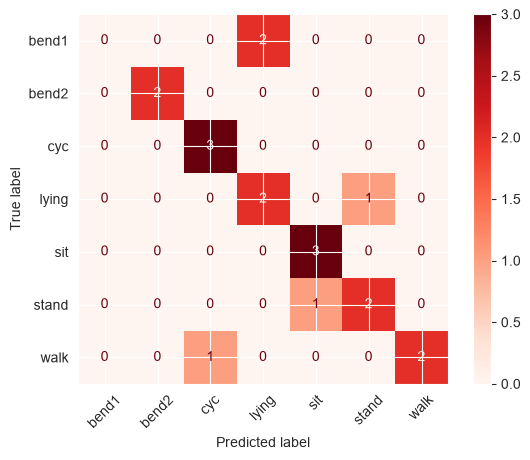

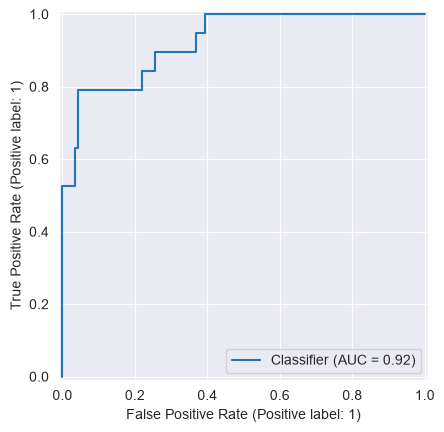

In [164]:
#CM and ROC
#confusion matrix
c_matrix = confusion_matrix(test_sample['class'], best_l1.predict(test_x))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['bend1', 'bend2', 'cyc', 'lying', 'sit', 'stand', 'walk'])
disp.plot(cmap=plt.cm.Reds, xticks_rotation=45)
plt.show()

#ROC and AUC
scores = best_l1.predict_proba(test_x)
auc = roc_auc_score(test_sample['class'], scores, multi_class='ovr', average='macro')
y_bin = pd.get_dummies(test_sample['class']).to_numpy()
RocCurveDisplay.from_predictions(y_bin.ravel(), scores.ravel())
plt.show()

#### ii. Naive Bayes

In [184]:
bayes_output = pd.DataFrame({'k': [], 'gauss': [], 'multi': []})
for k in range(1, 21):
    data = {}
    sample = split_features_class(training_data, k)
    sel_x1 = sample.drop(columns='class')
    data['k'] = int(k)
    data['gauss'] = cross_val_score(GaussianNB(), sel_x1, sample['class'], cv=4, scoring='accuracy').mean()
    data['multi'] = cross_val_score(MultinomialNB(), sel_x1, sample['class'], cv=4, scoring='accuracy').mean()
    bayes_output = pd.concat([bayes_output, pd.DataFrame([data])], ignore_index=True)
best_gauss = int(bayes_output.loc[bayes_output['gauss'].idxmax(), 'k'])
best_multi = int(bayes_output.loc[bayes_output['multi'].idxmax(), 'k'])

#gauss
sample = split_features_class(training_data, best_gauss)
gauss_test_sample = split_features_class(testing_data, best_gauss)
gauss = GaussianNB().fit(sample.drop(columns='class'), sample['class'])
gauss_acc = gauss.score(gauss_test_sample.drop(columns='class'), gauss_test_sample['class'])

#multi
sample = split_features_class(training_data, best_multi)
multi_test_sample = split_features_class(testing_data, best_multi)
multi = MultinomialNB().fit(sample.drop(columns='class'), sample['class'])
multi_acc = multi.score(multi_test_sample.drop(columns='class'), multi_test_sample['class'])

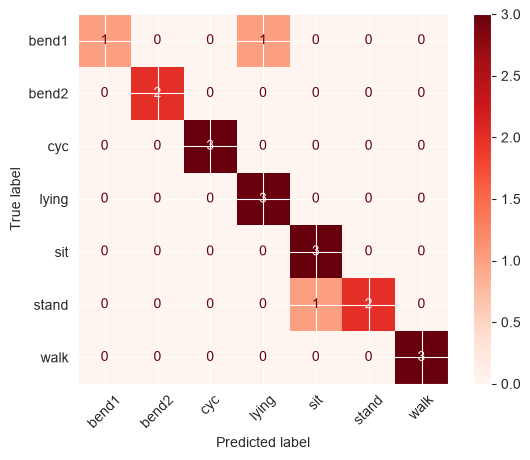

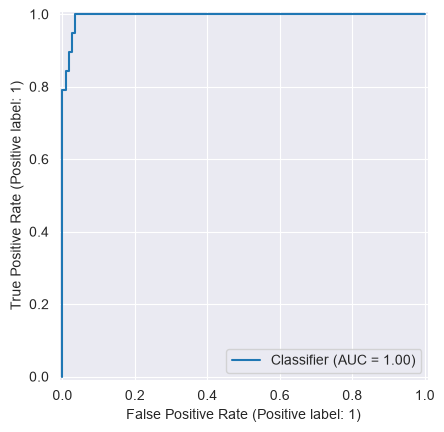

0.9910714285714286


In [183]:
#CM and ROC gauss
#confusion matrix
c_matrix = confusion_matrix(test_sample['class'], gauss.predict(gauss_test_sample.drop(columns='class')))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['bend1', 'bend2', 'cyc', 'lying', 'sit', 'stand', 'walk'])
disp.plot(cmap=plt.cm.Reds, xticks_rotation=45)
plt.show()

#ROC and AUC
scores = gauss.predict_proba(gauss_test_sample.drop(columns='class'))
auc = roc_auc_score(test_sample['class'], scores, multi_class='ovr', average='macro')
y_bin = pd.get_dummies(test_sample['class']).to_numpy()
RocCurveDisplay.from_predictions(y_bin.ravel(), scores.ravel())
plt.show()
print(auc)

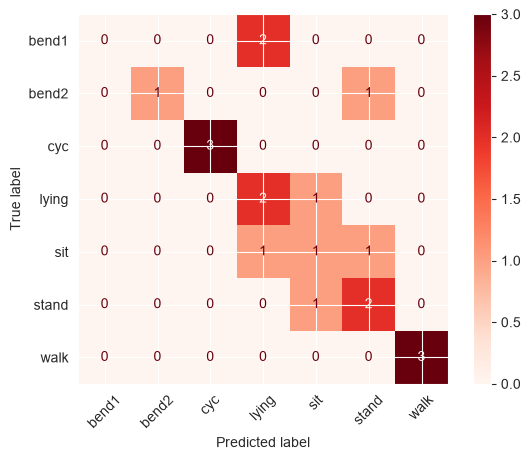

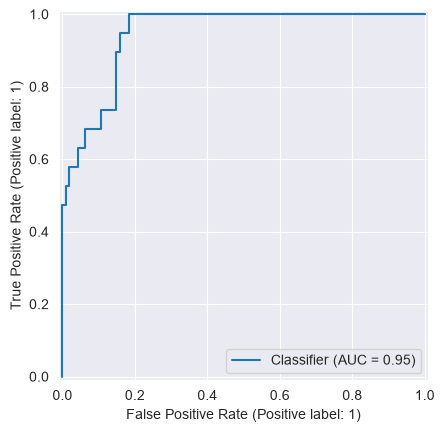

0.9494047619047619


In [185]:
#CM and ROC multi
#confusion matrix
c_matrix = confusion_matrix(test_sample['class'], multi.predict(multi_test_sample.drop(columns='class')))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['bend1', 'bend2', 'cyc', 'lying', 'sit', 'stand', 'walk'])
disp.plot(cmap=plt.cm.Reds, xticks_rotation=45)
plt.show()

#ROC and AUC
scores = multi.predict_proba(multi_test_sample.drop(columns='class'))
auc = roc_auc_score(test_sample['class'], scores, multi_class='ovr', average='macro')
y_bin = pd.get_dummies(test_sample['class']).to_numpy()
RocCurveDisplay.from_predictions(y_bin.ravel(), scores.ravel())
plt.show()
print(auc)

#### ii. Comparison

For multi-class classification, the Naive Bayes with Gaussian priors is superior to both L1 and multinominal models. It achieves greater accuracy, AUC, and CM patterns.

## 3. ISLR 4.8.3

The normal density function itself contains a quadratic function, this term persists in the function, provided the difference of coefficients for this term is not zero.

## 4. ISLR 4.8.7

find P(Y|x=4)
P(Y|x=4) = (P(Y)*P(4|Y))/(P(Y)*P(4|Y)+P(N)*P(4|N))
P(Y|x=4) = (0.8*P(4|Y))/(0.8*P(4|Y)+0.2*P(4|N))
    P(4|Y) = 1/(6*sqrt(2*pi))*e^-((4-10)^2/(2*36))
            = 0.0403284541
    P(4|N) = 1/(6*sqrt(2*pi))*e^-((4-0)^2/(2*36))
        = 0.0532413343
P(Y|x=4) = (0.8*0.0403)/(0.8*0.0403+0.2*0.0532)
= 0.7519


## Reference Materials

reference used https://www.geeksforgeeks.org/machine-learning/